# Ordinary Differential Equations and the Laplace Transform

Every transfer function in this book, starting with *Block Diagram*, is
built on one move: turning a linear ODE into an algebraic equation in
$s$. This page makes that move explicit before relying on it — solving a
constant-coefficient ODE directly, then again via the Laplace transform, and
showing the two answers agree.


In [2]:
from sympy import *
init_printing()


## 1. Linear ODEs with Constant Coefficients

Physical systems in this book (the rectilinear system, the flyball
governor, ...) are modeled by linear, constant-coefficient ODEs. SymPy's
`dsolve` solves these directly, symbolically, given initial conditions.

Take the damped mass-spring system as a running example:

$$
\ddot{x} + 3\dot{x} + 2x = 0, \qquad x(0) = 1,\ \dot{x}(0) = 0
$$


In [3]:
t = symbols('t', positive=True)
x = Function('x')

ode = Eq(x(t).diff(t, 2) + 3 * x(t).diff(t) + 2 * x(t), 0)
ics = {x(0): 1, x(t).diff(t).subs(t, 0): 0}

sol_dsolve = dsolve(ode, x(t), ics=ics)
sol_dsolve


Keep this result — Section 4 solves the *same* ODE through the
Laplace transform instead, and the two should match exactly.


## 2. The Laplace Transform

The (unilateral) Laplace transform of a time-domain function $f(t)$,
defined for $t \geq 0$, is

$$
F(s) = \mathcal{L}\{f(t)\} = \int_0^\infty f(t)\, e^{-st}\, dt
$$

SymPy computes this integral symbolically for the standard signals used
throughout the book.


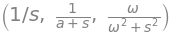

In [3]:
t, s, a, omega = sp.symbols('t s a omega', positive=True)
f = sp.Function('f')

# Unit step
step_L = sp.laplace_transform(1, t, s, noconds=True)

# Exponential decay
exp_L = sp.laplace_transform(sp.exp(-a * t), t, s, noconds=True)

# Sinusoid
sin_L = sp.laplace_transform(sp.sin(omega * t), t, s, noconds=True)

step_L, exp_L, sin_L


These three transform pairs — step, exponential, sinusoid — are the
building blocks behind essentially every input and every pole location
used later in the book.


## 3. Key Properties

### Linearity

$$
\mathcal{L}\{af(t) + bg(t)\} = aF(s) + bG(s)
$$

Immediate from the integral definition, since integration is linear.

### The Differentiation Property

This is the property that makes transfer functions possible:

$$
\mathcal{L}\{\dot{f}(t)\} = sF(s) - f(0)
$$

$$
\mathcal{L}\{\ddot{f}(t)\} = s^2F(s) - sf(0) - \dot{f}(0)
$$

Every derivative in an ODE becomes a power of $s$ — under **zero initial
conditions**, $\dot{f}(t) \to sF(s)$ exactly, which is why "$s$" is so
often described as standing in for "$d/dt$" in this book's earlier
chapters.

Let's verify this symbolically for a generic function.


In [4]:
f_t = sp.Function('f')(t)
f0 = sp.symbols('f0')  # f(0)

# SymPy's laplace_transform on a derivative directly
deriv_L = sp.laplace_transform(f_t.diff(t), t, s, noconds=True)
deriv_L


SymPy returns this in terms of the transform of $f(t)$ itself
(written `LaplaceTransform(f(t), t, s)`), plus the initial-condition term
— exactly the differentiation property stated above.


### Time-Shift and Convolution

$$
\mathcal{L}\{f(t-\tau)u(t-\tau)\} = e^{-s\tau}F(s)
$$

$$
\mathcal{L}\{f(t) * g(t)\} = F(s)\,G(s)
$$

Convolution in time becomes ordinary multiplication in the Laplace
domain — this is *why* cascading blocks in a block diagram corresponds to
multiplying their transfer functions.


## 4. Solving an ODE via the Laplace Transform

Now solve the same ODE from Section 1
($\ddot{x} + 3\dot{x} + 2x = 0,\ x(0)=1,\ \dot{x}(0)=0$), but this time by
hand-transforming it into an algebraic equation in $s$, solving for $X(s)$,
then inverse-transforming.


In [5]:
X = sp.symbols('X')  # stand-in for X(s)

x0_val, xdot0_val = 1, 0

# Apply the differentiation property term by term:
# L{x''} = s^2 X(s) - s*x(0) - x'(0)
# L{x'}  = s X(s) - x(0)
# L{x}   = X(s)
algebraic_eq = sp.Eq(
    (s**2 * X - s * x0_val - xdot0_val) + 3 * (s * X - x0_val) + 2 * X,
    0
)
algebraic_eq


In [6]:
X_s = sp.solve(algebraic_eq, X)[0]
X_s = sp.apart(X_s, s)  # partial fractions, ready for term-by-term inversion
X_s


In [7]:
x_t = sp.inverse_laplace_transform(X_s, s, t)
sp.simplify(x_t)


Compare this against `sol_dsolve` from Section 1 — same answer,
reached by transforming the problem into algebra, solving it there, and
transforming back. This detour through $s$ is exactly what every transfer
function in this book is implicitly doing.


## 5. Transfer Functions from Laplace

For a general linear ODE relating input $u(t)$ to output $y(t)$, Laplace-
transforming **under zero initial conditions** turns every derivative into
a power of $s$, leaving a purely algebraic relationship:

$$
a_n y^{(n)} + \cdots + a_0 y = b_m u^{(m)} + \cdots + b_0 u
\quad\xrightarrow{\mathcal{L},\ \text{zero I.C.}}\quad
(a_n s^n + \cdots + a_0)\,Y(s) = (b_m s^m + \cdots + b_0)\,U(s)
$$

$$
G(s) = \frac{Y(s)}{U(s)} = \frac{b_m s^m + \cdots + b_0}{a_n s^n + \cdots + a_0}
$$

This is precisely the transfer function used from *Block Diagram* onward.
The zero-initial-condition assumption is what lets $G(s)$ depend only on
the system, not on how it happened to start — any nonzero initial
conditions just add extra terms (as seen explicitly in Section 4) on top
of this same $G(s)$.


In [8]:
m1, c1, k1 = sp.symbols('m c k', positive=True)
Y, U = sp.symbols('Y U')

# m*y'' + c*y' + k*y = u,  zero initial conditions
G = 1 / (m1 * s**2 + c1 * s + k1)
G


## 6. Initial Value and Final Value Theorems

Two shortcuts avoid inverse-transforming altogether when only the
endpoints of $f(t)$ are needed:

$$
f(0^+) = \lim_{s\to\infty} sF(s) \qquad \text{(Initial Value Theorem)}
$$

$$
f(\infty) = \lim_{s\to 0} sF(s) \qquad \text{(Final Value Theorem, valid only if } f(\infty) \text{ exists)}
$$

The Final Value Theorem is exactly the tool used on the *Tracking Accuracy
of a Feedback System* page to compute steady-state error directly from
$E(s)$, without ever inverse-transforming the error signal.


In [9]:
F_s = X_s  # reuse X(s) from Section 4

initial_value = sp.limit(s * F_s, s, sp.oo)
final_value = sp.limit(s * F_s, s, 0)

initial_value, final_value


Check against the time-domain solution: $x(0) = 1$ (matches the
initial value theorem) and $x(t) \to 0$ as $t\to\infty$ since both poles
($-1, -2$) are stable (matches the final value theorem).

## What's next

With ODEs and the Laplace transform established here, and rank/
eigenvalues/matrix-exponential established in the *Linear Algebra Primer*,
both *Block Diagram* and *State-Space Modeling* can now be read as two
different endpoints of the same starting point: a linear ODE.
